# PerfectPunch v21 — Lite Preprocessing + Lite ST-GCN Training + Live Webcam

This version extracts **new MediaPipe Lite** landmarks from all source videos into a separate `processed_data_lite_v21` folder, and stores new cross-validation checkpoints/results in `stratified5_lite_v21`. It preserves the v20 segmentation algorithm, 60 FPS interpolation, 50 frames, 7 feature channels, model architectures, training, and live demo.

**Important:** Old Heavy `.npy` files and previous 94.17% accuracy must not be treated as Lite data/results. Re-run segmentation. To get a fair Lite held-out accuracy, set `RUN_EXPERIMENTS=True` and run Section 11 for the 5 Lite folds, then Section 15. Otherwise Section 15 can train on all 120 Lite clips with a heuristic 54 epochs, but cannot report independent accuracy.


## 0. Install & mount Google Drive

In [ ]:
!pip install -q "mediapipe>=0.10.30"   # 0.10.13 is no longer available on Colab
!pip install -q onnx onnxscript

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Global configuration — check these paths before running segmentation

In [ ]:
import os, glob, json, math, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset, WeightedRandomSampler
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, train_test_split
import matplotlib.pyplot as plt

SEED = 42
CLIP_FRAMES = 50
TARGET_FPS = 60  # MUST match the uploaded notebook / inference deployment
N_JOINTS = 33
CLASS_NAMES = ['jab', 'lead-hook', 'rear-uppercut']
N_CLASSES = len(CLASS_NAMES)
N_CHANNELS = 7
ARM_JOINTS = [13, 14, 15, 16]
N_ARM_JOINTS = len(ARM_JOINTS)
VELOCITY_LM = [11, 12, 13, 14, 15, 16]
VEL_WINDOW = 5

# The team's shared cloud folder must first be accessible at this mounted path.
# Edit this line to match your Google Drive shortcut location.
POSE_VARIANT = 'lite'  # preprocessing AND live webcam; 'lite' | 'full' | 'heavy'
assert POSE_VARIANT in ('lite', 'full', 'heavy')
INPUT_FOLDER = '/content/drive/MyDrive/newPerfectPunchData/punch_dataset'
DRIVE_OUTPUT_BASE = '/content/drive/MyDrive/newPerfectPunchData/processed_data_lite_v21'
DRIVE_NPY = os.path.join(DRIVE_OUTPUT_BASE, 'npy_data')
RUN_DIR = '/content/drive/MyDrive/newPerfectPunchData/stratified5_lite_v21'
CLASS_FOLDERS = {
    'jab': ['jab'],
    'lead-hook': ['hook', 'lead-hook'],
    'rear-uppercut': ['uppercut', 'rear-uppercut'],
}
VIDEO_EXTENSIONS = ('.mp4', '.mov', '.avi', '.m4v')

def class_folder(root, label):
    found = [Path(root)/name for name in CLASS_FOLDERS[label] if (Path(root)/name).is_dir()]
    if len(found) > 1:
        raise ValueError(f'Ambiguous source folders for {label}: {found}. Keep just one of the aliases.')
    return str(found[0]) if found else None

def source_videos(folder):
    return sorted([p for p in Path(folder).iterdir() if p.is_file() and p.suffix.lower() in VIDEO_EXTENSIONS],
                  key=lambda p: p.name.lower())

# Processing: False for quick re-runs after the .npy files exist.
AUTO_SEGMENT = True
FORCE_REPROCESS = False   # New Lite output folder is empty; set True if you already wrote incorrect .npy here

# Training-only augmentation. `v12` is identical to the uploaded source.
AUGMENTATION_MODE = 'v12'  # 'v12', 'improved', or 'none'
HOOK_SPECIFIC_AUG = False  # only in improved mode
MIRROR_PROB = 0.5          # only in improved mode
AUGMENT_TRAIN = True
SAMPLER_MODE = 'hook_x3'   # 'hook_x3', 'balanced', 'shuffle'

N_SPLITS = 5  # True stratified 5-fold CV: ~20% test per fold, balanced by punch label
VAL_FRACTION = 0.15  # fraction of the remaining 80%, not of the full dataset
MAX_FOLDS = None  # None = all 5 folds; e.g. 2 for a quick debug run
MODEL_NAMES = ['tcn', 'tiny_cnn', 'stgcn', 'transformer', 'tiny_dinat']
MODELS_TO_RUN = [
    'tcn',
    'stgcn',
    'tiny_dinat'
]

EPOCHS, PATIENCE = 120, 20
BATCH_SIZE, LR, WEIGHT_DECAY = 16, 3e-4, 1e-3
NUM_WORKERS = 0
RUN_EXPERIMENTS = True  # training is opt-in

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
assert os.path.isdir(INPUT_FOLDER), f'Raw videos not found: {INPUT_FOLDER}. Check the shared Drive shortcut/path.'
os.makedirs(DRIVE_NPY, exist_ok=True)
os.makedirs(RUN_DIR, exist_ok=True)
for label in CLASS_NAMES:
    folder = class_folder(INPUT_FOLDER, label)
    print(f'{label:<15} <- {folder} ({len(source_videos(folder)) if folder else 0} videos)')
    if folder is None:
        raise FileNotFoundError(f'Missing source folder for {label}: expected one of {CLASS_FOLDERS[label]}')
print('Config ready | pose:', POSE_VARIANT, '| features:', N_CHANNELS, '| FPS:', TARGET_FPS, '| RAW:', INPUT_FOLDER)
print('Processed Lite data:', DRIVE_NPY, '| Lite results:', RUN_DIR)

jab             <- /content/drive/MyDrive/newPerfectPunchData/punch_dataset/jab (40 videos)
lead-hook       <- /content/drive/MyDrive/newPerfectPunchData/punch_dataset/hook (40 videos)
rear-uppercut   <- /content/drive/MyDrive/newPerfectPunchData/punch_dataset/uppercut (40 videos)
Config ready | pose: lite | features: 7 | FPS: 60 | RAW: /content/drive/MyDrive/newPerfectPunchData/punch_dataset
Processed Lite data: /content/drive/MyDrive/newPerfectPunchData/processed_data_lite_v21/npy_data | Lite results: /content/drive/MyDrive/newPerfectPunchData/stratified5_lite_v21


## 2. Raw video → MediaPipe **Lite** skeleton → 60 FPS → 50-frame punch

The extractor chooses `POSE_VARIANT` from Section 1. It uses MediaPipe `RunningMode.VIDEO`, the same 60 FPS resampling, normalization and segmentation as v20. Use fresh output `.npy` under `processed_data_lite_v21` — do not reuse Heavy features.


In [ ]:
import os
import cv2
import mediapipe as mp
import numpy as np
import glob

import urllib.request
from mediapipe.tasks.python import BaseOptions, vision

# mediapipe >= 0.10.30 removed mp.solutions, so pose runs through the Tasks
# PoseLandmarker. Keep extraction model consistent with the final live demo.
POSE_TASK = f'/content/pose_landmarker_{POSE_VARIANT}.task'
if not os.path.exists(POSE_TASK):
    urllib.request.urlretrieve(
        'https://storage.googleapis.com/mediapipe-models/pose_landmarker/'
        f'pose_landmarker_{POSE_VARIANT}/float16/latest/'
        f'pose_landmarker_{POSE_VARIANT}.task', POSE_TASK)


def make_pose_landmarker():
    return vision.PoseLandmarker.create_from_options(vision.PoseLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=POSE_TASK),
        running_mode=vision.RunningMode.VIDEO,
        num_poses=1,
        min_pose_detection_confidence=0.5,
        min_tracking_confidence=0.5,
    ))

L_WRIST_IDX, R_WRIST_IDX = 15, 16
L_ELBOW_IDX, R_ELBOW_IDX = 13, 14


def normalize_skeleton(world_lm_list):
    """
    Hip-centred, shoulder-width-normalised from pose_world_landmarks.
    World frame: x=lateral, y=vertical (up), z=depth toward camera.
    Returns (33, 4) — [x, y, z, 1.0].
    """
    coords = np.array([[l.x, l.y, l.z] for l in world_lm_list], dtype=np.float32)
    hip_c  = (coords[23] + coords[24]) / 2.0
    coords -= hip_c
    dist   = np.linalg.norm(coords[11] - coords[12])
    if dist > 1e-6:
        coords /= dist
    vis = np.ones((33, 1), dtype=np.float32)
    return np.concatenate([coords, vis], axis=1)


def smooth_signal(arr, window=VEL_WINDOW):
    kernel = np.ones(window) / window
    return np.convolve(arr, kernel, mode='same')


def resample_frames(frames, src_fps, dst_fps=TARGET_FPS):
    """Temporally resample skeleton frames from src_fps to dst_fps (copied from the app)."""
    n_src = len(frames)
    if n_src < 2 or abs(src_fps - dst_fps) < 0.5:
        return np.array(frames, dtype=np.float32)
    arr   = np.array(frames, dtype=np.float32)       # (N, 33, 4)
    dur   = n_src / src_fps
    n_dst = max(2, int(round(dur * dst_fps)))
    t_src = np.linspace(0, 1, n_src)
    t_dst = np.linspace(0, 1, n_dst)
    out   = np.zeros((n_dst, arr.shape[1], arr.shape[2]), dtype=np.float32)
    for j in range(arr.shape[1]):
        for c in range(arr.shape[2]):
            out[:, j, c] = np.interp(t_dst, t_src, arr[:, j, c])
    return out


def read_video_frames(video_path):
    """
    Read every detected-pose frame, then resample to TARGET_FPS.
    Returns (frames, TARGET_FPS).
    """
    cap     = cv2.VideoCapture(video_path)
    src_fps = cap.get(cv2.CAP_PROP_FPS)
    if src_fps <= 0 or src_fps > 500:
        src_fps = 30.0

    frames = []
    # Fresh landmarker per video: VIDEO mode needs increasing timestamps
    with make_pose_landmarker() as landmarker:
        i = 0
        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break
            rgb = np.ascontiguousarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            res = landmarker.detect_for_video(
                mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb), int(i * 1000 / src_fps))
            i += 1
            if res.pose_world_landmarks and res.pose_landmarks:
                frames.append(normalize_skeleton(res.pose_world_landmarks[0]))
    cap.release()
    if len(frames) == 0:
        return [], TARGET_FPS
    return resample_frames(frames, src_fps, TARGET_FPS), TARGET_FPS


def find_reversal_frame(frames, src_fps):
    """
    Find where the punching arm starts retracting after impact.

    1. Find the compound-speed peak (moment of max extension).
    2. Determine the dominant motion axis using the FULL pre-peak window
       (average of both wrists AND both elbows for robustness).
           x = lateral  → lead-hook
           y = vertical → rear-uppercut
           z = forward  → jab
    3. Search up to 1 second (src_fps frames) AFTER the peak for a
       sign reversal on the dominant axis of the active arm.
    4. If no reversal found (video ends before retraction):
           → use the LAST frame of the video as the clip end.
       This ensures the window always contains as much of the punch as
       possible — rather than ending exactly at impact (the old fallback).

    Returns (clip_end_frame, peak_idx, dominant_axis_char).
    """
    xyz = np.array([f[:, :3] for f in frames], dtype=np.float32)  # (T, 33, 3)
    T   = xyz.shape[0]

    lw = xyz[:, L_WRIST_IDX, :]
    rw = xyz[:, R_WRIST_IDX, :]
    le = xyz[:, L_ELBOW_IDX, :]
    re = xyz[:, R_ELBOW_IDX, :]

    def vel(pos):
        v = np.zeros_like(pos)
        v[1:] = pos[1:] - pos[:-1]
        return v

    lw_v = vel(lw); rw_v = vel(rw)
    le_v = vel(le); re_v = vel(re)

    # Compound speed across all 4 arm joints
    compound = np.sqrt((
        np.sum(lw_v**2, axis=1) + np.sum(rw_v**2, axis=1) +
        np.sum(le_v**2, axis=1) + np.sum(re_v**2, axis=1)
    ) / 4.0)
    compound_s = smooth_signal(compound)

    # Peak must leave room for CLIP_FRAMES before it; relax if video is short
    min_peak = min(CLIP_FRAMES - 1, T - 1)
    peak     = int(np.argmax(compound_s[min_peak:])) + min_peak

    # ── Dominant axis — use FULL pre-peak window, all 4 joints ───────────────
    # Averaging wrists and elbows together makes the vote more robust when
    # one joint has noisy tracking (common for rear wrist in uppercuts).
    ws = slice(0, peak + 1)
    mean_abs = np.array([
        np.mean(np.abs(lw_v[ws, 0]) + np.abs(rw_v[ws, 0]) +
                np.abs(le_v[ws, 0]) + np.abs(re_v[ws, 0])),  # x
        np.mean(np.abs(lw_v[ws, 1]) + np.abs(rw_v[ws, 1]) +
                np.abs(le_v[ws, 1]) + np.abs(re_v[ws, 1])),  # y
        np.mean(np.abs(lw_v[ws, 2]) + np.abs(rw_v[ws, 2]) +
                np.abs(le_v[ws, 2]) + np.abs(re_v[ws, 2])),  # z
    ])
    dom_axis  = int(np.argmax(mean_abs))
    axis_char = ['x', 'y', 'z'][dom_axis]

    # Active wrist: whichever moved more on the dominant axis before peak
    lw_dom_mean = np.mean(np.abs(lw_v[ws, dom_axis]))
    rw_dom_mean = np.mean(np.abs(rw_v[ws, dom_axis]))
    dom_v = smooth_signal(
        lw_v[:, dom_axis] if lw_dom_mean >= rw_dom_mean else rw_v[:, dom_axis]
    )

    sign_at_peak = np.sign(dom_v[peak]) if abs(dom_v[peak]) > 1e-6 else 1.0

    # Search up to 1 second after peak for sign reversal
    search_end = min(peak + int(src_fps) + 1, T)
    reversal_found = False

    clip_end = T - 1   # default: use last frame if no reversal found
    for i in range(peak + 1, search_end):
        if abs(dom_v[i]) > 1e-6 and np.sign(dom_v[i]) != sign_at_peak:
            clip_end = i
            reversal_found = True
            break

    return clip_end, peak, axis_char, reversal_found


def extract_best_clip(video_path):
    """
    Read video at native FPS, find the arm reversal (or last frame if no
    reversal), return the CLIP_FRAMES window ending there.
    Pads the front (repeating the first frame) if fewer frames exist before the endpoint.
    Never skips a video due to length.
    """
    frames, src_fps = read_video_frames(video_path)

    if len(frames) == 0:
        print(f"      ⚠️  No pose detected — skipping")
        return None

    clip_end, peak, axis, found = find_reversal_frame(frames, src_fps)

    end   = clip_end + 1
    start = end - CLIP_FRAMES

    if start < 0:
        pad_len = -start
        clip    = np.array(frames[0:end])
        padding = np.repeat(clip[:1], pad_len, axis=0)
        clip    = np.concatenate([padding, clip], axis=0)
    else:
        clip = np.array(frames[start:end])

    reversal_str = f"reversal@{clip_end}" if found else f"no-reversal→last@{clip_end}"
    print(f"      src_fps={src_fps:.1f}  dom={axis}  peak@{peak}  "
          f"{reversal_str}  window[{max(0,end-CLIP_FRAMES)}:{end}]  "
          f"frames_total={len(frames)}")
    return clip

In [ ]:
def segment_all(force=FORCE_REPROCESS):
    """One original video -> one .npy; unchanged extractor, explicit collision checks."""
    n_saved, n_reused, n_failed = 0, 0, 0
    for label in CLASS_NAMES:
        src = class_folder(INPUT_FOLDER, label)
        dst = Path(DRIVE_NPY) / label
        dst.mkdir(parents=True, exist_ok=True)
        videos = source_videos(src)
        stems = [p.stem.lower() for p in videos]
        if len(stems) != len(set(stems)):
            raise ValueError(f'Duplicate video stems in {src}; .mp4 and .mov can overwrite the same .npy')
        print(f'\n{label}: {len(videos)} source videos in {src}')
        for video in videos:
            target = dst / (video.stem + '.npy')
            if target.is_file() and not force:
                n_reused += 1
                continue
            clip = extract_best_clip(str(video))
            if clip is None:
                n_failed += 1
                print('  No detected skeleton:', video)
                continue
            assert clip.shape == (CLIP_FRAMES, N_JOINTS, 4), (video, clip.shape)
            np.save(target, clip.astype(np.float32))
            n_saved += 1
    print(f'Segmentation: saved={n_saved} reused={n_reused} failed={n_failed} | {DRIVE_NPY}')

if AUTO_SEGMENT:
    segment_all()


jab: 40 source videos in /content/drive/MyDrive/newPerfectPunchData/punch_dataset/jab
      src_fps=60.0  dom=z  peak@49  reversal@54  window[5:55]  frames_total=66
      src_fps=60.0  dom=z  peak@49  reversal@50  window[1:51]  frames_total=64
      src_fps=60.0  dom=z  peak@49  reversal@52  window[3:53]  frames_total=60
      src_fps=60.0  dom=z  peak@49  reversal@58  window[9:59]  frames_total=74
      src_fps=60.0  dom=y  peak@49  no-reversal→last@51  window[2:52]  frames_total=52
      src_fps=60.0  dom=x  peak@55  no-reversal→last@57  window[8:58]  frames_total=58
      src_fps=60.0  dom=z  peak@53  reversal@56  window[7:57]  frames_total=80
      src_fps=60.0  dom=x  peak@49  no-reversal→last@49  window[0:50]  frames_total=50
      src_fps=60.0  dom=z  peak@50  reversal@55  window[6:56]  frames_total=68
      src_fps=60.0  dom=x  peak@54  reversal@63  window[14:64]  frames_total=66
      src_fps=60.0  dom=z  peak@49  reversal@62  window[13:63]  frames_total=64
      src_fps=60.0

## 3. Feature engineering — exactly the uploaded seven channels

The `build_tensor()` below is **byte-for-byte the same Python function** as in `Copy_of_newPerfectPunchModel.ipynb`. It outputs `(7,T,4,3)` with position, velocity, geometry, y-velocity, elbow angle, lateral dominance, and vertical dominance. No model-specific feature changes; deployed inference uses this function too.

In [ ]:
import numpy as np

L_SHOULDER, R_SHOULDER = 11, 12
L_ELBOW,    R_ELBOW    = 13, 14
L_WRIST,    R_WRIST    = 15, 16
L_HIP,      R_HIP      = 23, 24

# Tracked joint order: [L_elbow, R_elbow, L_wrist, R_wrist]  (indices 0-3)
TRACK    = [L_ELBOW, R_ELBOW, L_WRIST, R_WRIST]
SHOULDER = [L_SHOULDER, R_SHOULDER, L_SHOULDER, R_SHOULDER]


def angle_cos(a, b, c):
    ba = a - b; bc = c - b
    return float(np.dot(ba, bc) / (np.linalg.norm(ba) * np.linalg.norm(bc) + 1e-8))


def build_tensor(clip):
    """
    clip: (T, 33, 4)  — world-3D skeleton, columns [x, y, z, vis]
                        x = lateral (left/right), y = vertical (up/down),
                        z = depth (toward camera), shoulder-width normalised.

    Returns float32 tensor of shape (7, T, 4, 3).

    Channel layout
    --------------
    ch0  position xyz          [L_elbow, R_elbow, L_wrist, R_wrist]
    ch1  velocity xyz          frame-to-frame displacement (world 3-D)
    ch2  geometry              bone unit vectors; x-component of elbow rows
                               replaced by elbow flexion angle cosine
    ch3  y-velocity            raw vertical motion per joint (scalar broadcast)
                               (hook: elbow rises; uppercut: wrist rockets up)
    ch4  elbow flexion angle   cos(angle) broadcast to all 4 joint rows
                               (jab ~+1.0 = extended; hook/uppercut ~0.0-0.5)
    ch5  lateral dominance     signed x_vel / ||vel||  — how sideways is the motion?
                               jab  ≈ 0  (forward/z dominant)
                               hook ≈ ±1 (x dominant)
                               uppercut ≈ 0 (y dominant)
    ch6  vertical dominance    signed y_vel / ||vel||  — how upward is the motion?
                               jab      ≈ 0  (z dominant)
                               hook     ≈ 0  (x dominant, stays level)
                               uppercut ≈ +1 (y dominant — wrist drives steeply up)
    """
    T   = clip.shape[0]
    xyz = clip[:, :, :3].astype(np.float32)   # (T, 33, 3)

    tracked = xyz[:, TRACK, :]   # (T, 4, 3)

    # ── ch0: position ────────────────────────────────────────────────────────
    ch0 = tracked.copy()

    # ── ch1: velocity (world 3-D frame-to-frame displacement) ────────────────
    ch1     = np.zeros_like(tracked)
    ch1[1:] = tracked[1:] - tracked[:-1]

    # ── ch2: geometry — bone unit vectors + elbow flexion angle ──────────────
    ch2 = np.zeros_like(tracked)
    for t in range(T):
        f = xyz[t]
        for i in range(4):
            if i < 2:   # elbows: shoulder → elbow
                v = f[TRACK[i]] - f[SHOULDER[i]]
            else:       # wrists: elbow → wrist
                v = f[TRACK[i]] - f[TRACK[i - 2]]
            ch2[t, i] = v / (np.linalg.norm(v) + 1e-8)
        # Overwrite x-component of elbow rows with flexion angle cosine
        ch2[t, 0, 0] = angle_cos(f[L_SHOULDER], f[L_ELBOW], f[L_WRIST])
        ch2[t, 1, 0] = angle_cos(f[R_SHOULDER], f[R_ELBOW], f[R_WRIST])

    # ── ch3: y-velocity — raw vertical motion scalar ─────────────────────────
    # Distinct from ch6 (normalised): raw magnitude matters here — a fast
    # uppercut has large absolute y_vel even before normalising.
    ch3   = np.zeros_like(tracked)
    y_vel = np.zeros((T, 4), dtype=np.float32)
    for i, lm in enumerate(TRACK):
        y_vel[1:, i] = xyz[1:, lm, 1] - xyz[:-1, lm, 1]
    ch3[:, :, :] = y_vel[:, :, np.newaxis]   # broadcast to 3 cols

    # ── ch4: elbow flexion angle, broadcast to all 4 joint rows ──────────────
    ch4 = np.zeros_like(tracked)
    for t in range(T):
        f = xyz[t]
        l_angle = angle_cos(f[L_SHOULDER], f[L_ELBOW], f[L_WRIST])
        r_angle = angle_cos(f[R_SHOULDER], f[R_ELBOW], f[R_WRIST])
        ch4[t, 0, :] = l_angle
        ch4[t, 1, :] = r_angle
        ch4[t, 2, :] = l_angle
        ch4[t, 3, :] = r_angle

    # ── ch5 & ch6: lateral and vertical dominance ────────────────────────────
    # Both use the same denominator (total speed) so they form an
    # interpretable decomposition of motion direction.
    #
    #              jab    hook   uppercut
    #   ch5 (x):   ≈ 0    ≈ ±1    ≈ 0
    #   ch6 (y):   ≈ 0    ≈  0    ≈ +1   ← unique uppercut signature
    #
    # Together they triangulate all 3 classes cleanly.
    eps   = 1e-8
    vel   = ch1                                                   # (T, 4, 3)
    speed = np.linalg.norm(vel, axis=-1, keepdims=True) + eps    # (T, 4, 1)

    lat_dom  = vel[:, :, 0:1] / speed   # x_vel / ||vel||  (T, 4, 1)
    vert_dom = vel[:, :, 1:2] / speed   # y_vel / ||vel||  (T, 4, 1)

    ch5 = np.broadcast_to(lat_dom,  (T, 4, 3)).copy()
    ch6 = np.broadcast_to(vert_dom, (T, 4, 3)).copy()

    return np.stack([ch0, ch1, ch2, ch3, ch4, ch5, ch6], axis=0).astype(np.float32)

assert build_tensor(np.zeros((CLIP_FRAMES, 33, 4), np.float32)).shape == (7, CLIP_FRAMES, 4, 3)
print('Feature shape:', (7, CLIP_FRAMES, 4, 3))

Feature shape: (7, 50, 4, 3)


## 4. Video manifest (not subject IDs)

Class folder names are remapped to canonical output folders: `hook/` → `lead-hook/`, `uppercut/` → `rear-uppercut/`. Every **original video** corresponds to exactly one `.npy` item in the manifest. It checks processed clip availability and ignores unrelated stale `.npy` files rather than silently introducing extra training data. No `subject_mapping.csv` is needed.

In [ ]:
def build_manifest(raw_root=INPUT_FOLDER, npy_root=DRIVE_NPY):
    rows = []
    for class_id, label in enumerate(CLASS_NAMES):
        raw_dir = class_folder(raw_root, label)
        if raw_dir is None:
            raise FileNotFoundError(f'No raw folder for {label} (aliases: {CLASS_FOLDERS[label]})')
        videos = source_videos(raw_dir)
        if not videos:
            raise ValueError(f'No raw videos for {label}: {raw_dir}')
        stems = [p.stem.lower() for p in videos]
        if len(set(stems)) != len(stems):
            raise ValueError(f'Nonunique video stems for class {label}: {raw_dir}')
        for video in videos:
            processed = Path(npy_root) / label / (video.stem + '.npy')
            if not processed.is_file():
                raise FileNotFoundError(f'Missing processed clip for {video}: {processed}. Run segment_all().')
            clip = np.load(processed, mmap_mode='r')
            if clip.ndim != 3 or clip.shape[1:] != (33, 4) or clip.shape[0] < 1:
                raise ValueError(f'Bad clip {processed}: {clip.shape}, expected (T,33,4)')
            rows.append({'path': str(processed), 'video_path':str(video),
                         'video_id':f'{label}/{video.stem}',
                         'relative_path':f'{label}/{video.stem}.npy',
                         'label':int(class_id), 'class_name':label})
    df = pd.DataFrame(rows).reset_index(drop=True)
    assert df.video_id.is_unique
    df.to_csv(Path(RUN_DIR)/'video_manifest.csv', index=False)
    print('Video counts:',df.class_name.value_counts().reindex(CLASS_NAMES,fill_value=0).to_dict(), '| Total:',len(df))
    return df

# After segmentation: manifest = build_manifest()

## 5. Training augmentation and datasets

The default **v12 augmentation function is copied exactly from the uploaded notebook** (even its old mirror and warping behavior); `improved` is optional, or choose `none` for an ablation. Augmentation occurs only for training, **never** for validation, held-out test, or deployment. The video preprocessing and seven-channel tensor remain unchanged.

When short `.npy` files are encountered, `prepare_raw_clip` uses the **first-frame front padding** rule consistent with this uploaded notebook, not the older latestData zero-padding convention.

In [ ]:
def augment_clip(clip, label_name=None):
    """(T, 33, 4) -> augmented clip. Hooks get stronger augmentation."""
    clip     = clip.copy()
    xyz      = clip[:, :, :3]
    is_hook  = (label_name == 'lead-hook')

    # Mirror left <-> right
    if np.random.random() > 0.5:
        xyz[:, :, 0] = -xyz[:, :, 0]

    # Temporal speed warp
    T     = xyz.shape[0]
    warp  = 0.35 if is_hook else 0.25
    speed = np.random.uniform(1 - warp, 1 + warp)
    src   = np.linspace(0, T - 1, max(int(T * speed), T // 2))
    warped = np.array([xyz[min(int(i), T - 1)] for i in src])
    idx    = np.linspace(0, len(warped) - 1, T)
    xyz    = np.array([warped[min(int(i), len(warped) - 1)] for i in idx])

    # Yaw rotation (larger for hooks to cover more lateral angles)
    max_yaw = 40 if is_hook else 25
    ang = np.random.uniform(-max_yaw, max_yaw) * np.pi / 180
    c, s = np.cos(ang), np.sin(ang)
    R    = np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]], dtype=np.float32)
    xyz  = xyz @ R.T

    # Scale jitter +-12%
    xyz *= np.random.uniform(0.88, 1.12)

    # Gaussian noise
    noise_std = 0.007 if is_hook else 0.005
    xyz += np.random.normal(0, noise_std, xyz.shape).astype(np.float32)

    # Hook-specific: pitch tilt to simulate elbow height variation
    if is_hook and np.random.random() > 0.4:
        pitch = np.random.uniform(-15, 15) * np.pi / 180
        cp, sp = np.cos(pitch), np.sin(pitch)
        Rp = np.array([[1, 0, 0], [0, cp, -sp], [0, sp, cp]], dtype=np.float32)
        xyz = xyz @ Rp.T

    clip[:, :, :3] = xyz
    return clip


# Mirror pairs from MediaPipe's 33 landmark schema (excluding midline landmarks).
_MIRROR_PAIRS = [(1,4),(2,5),(3,6),(7,8),(9,10),(11,12),(13,14),(15,16),
                 (17,18),(19,20),(21,22),(23,24),(25,26),(27,28),(29,30),(31,32)]
_MIRROR_IDX = np.arange(33)
for a,b in _MIRROR_PAIRS:
    _MIRROR_IDX[a],_MIRROR_IDX[b] = b,a

def augment_clip_improved(clip, label_name=None):
    clip = clip.copy()
    xyz = clip[:,:,:3].copy()
    is_hook = HOOK_SPECIFIC_AUG and label_name == 'lead-hook'
    if np.random.rand() < MIRROR_PROB:
        xyz = xyz[:,_MIRROR_IDX,:].copy()
        xyz[:,:,0] *= -1

    # Resample the sequence at a randomized playback speed, retaining output T.
    T = len(xyz)
    speed = np.random.uniform(0.65 if is_hook else 0.75,
                              1.35 if is_hook else 1.25)
    center = (T - 1) / 2
    src = np.clip((np.arange(T)-center) * speed + center, 0, T-1)
    lo, hi = np.floor(src).astype(int), np.ceil(src).astype(int)
    a = (src - lo).astype(np.float32)[:,None,None]
    xyz = xyz[lo]*(1-a) + xyz[hi]*a

    yaw_deg = 40 if is_hook else 25
    ang = np.deg2rad(np.random.uniform(-yaw_deg, yaw_deg))
    c,s = np.cos(ang),np.sin(ang)
    yaw = np.array([[c,0,s],[0,1,0],[-s,0,c]],dtype=np.float32)
    xyz = xyz @ yaw.T
    xyz *= np.random.uniform(0.88,1.12)
    xyz += np.random.normal(0,0.007 if is_hook else 0.005,xyz.shape).astype(np.float32)
    if is_hook and np.random.rand() > 0.4:
        a = np.deg2rad(np.random.uniform(-15,15)); c,s = np.cos(a),np.sin(a)
        pitch = np.array([[1,0,0],[0,c,-s],[0,s,c]],dtype=np.float32)
        xyz = xyz @ pitch.T
    clip[:,:,:3] = xyz
    return clip



def apply_train_augmentation(clip, label_name):
    if AUGMENTATION_MODE == 'none': return clip
    if AUGMENTATION_MODE == 'v12': return augment_clip(clip, label_name)
    if AUGMENTATION_MODE == 'improved': return augment_clip_improved(clip, label_name)
    raise ValueError(f'Unknown AUGMENTATION_MODE: {AUGMENTATION_MODE}')

def prepare_raw_clip(raw):
    raw = np.asarray(raw, dtype=np.float32)
    if raw.ndim != 3 or raw.shape[1:] != (33,4) or len(raw) == 0:
        raise ValueError(f'Expected (T,33,4) skeleton, got {raw.shape}')
    if len(raw) < CLIP_FRAMES:
        padding = np.repeat(raw[:1], CLIP_FRAMES-len(raw), axis=0)
        raw = np.concatenate((padding,raw),axis=0)
    elif len(raw) > CLIP_FRAMES:
        # Extraction guarantees 50; fail on a stale/incorrect upstream clip.
        raise ValueError(f'Expected 50-frame segmented clip, got {len(raw)}. Reprocess with segment_all(force=True).')
    return raw

class BoxingDataset(Dataset):
    def __init__(self, manifest, augment=False):
        self.frame = manifest.reset_index(drop=True)
        self.augment = augment
    def __len__(self): return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[int(idx)]
        raw = prepare_raw_clip(np.load(row.path))
        if self.augment: raw = apply_train_augmentation(raw, row.class_name)
        feat = build_tensor(raw)
        if not np.isfinite(feat).all():
            raise ValueError(f'Non-finite features in {row.path}')
        return torch.from_numpy(feat), torch.tensor(int(row.label), dtype=torch.long)

## 6. Stratified 5-Fold Cross-Validation (video-level)

Use `sklearn.model_selection.StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)` to allocate **whole videos** to five mutually exclusive test folds. The stratification variable is the **punch label**, not the person's identity or filename. With 40 videos per class, each fold's test set has exactly **8 jab + 8 hook + 8 uppercut = 24 videos**.

For each fold, take the remaining 96 videos and create an **independent stratified validation split** (`VAL_FRACTION=0.15`): **81 train / 15 val / 24 test** for the current balanced 120-video dataset. Test never enters training, early stopping, or checkpoint selection. No augmentation in validation or test. All architectures share the same fixed folds.

`MAX_FOLDS=2` runs only two of the five folds for a smoke test, and is **not** a complete cross-validation result. `MAX_FOLDS=None` evaluates all five folds, covering each video as test exactly once. Videos from the same **person** can appear in both training and test: this evaluates new recordings, not unseen people.


In [ ]:
def iter_stratified5_folds(manifest, seed=SEED, max_folds=MAX_FOLDS):
    """Yield 5 stratified VIDEO-level test folds, with separate stratified validation.

    One video = one manifest row. No grouping by individual is performed.
    All videos are held out exactly once as test when max_folds is None.
    """
    manifest = manifest.reset_index(drop=True)
    n = len(manifest)
    labels = manifest.label.to_numpy(dtype=int)
    video_ids = manifest.video_id.astype(str).to_numpy()
    if len(set(video_ids)) != n:
        raise ValueError('video_id must be unique: do not treat clips from one video as independent samples.')
    counts = np.bincount(labels, minlength=N_CLASSES)
    if len(labels) == 0 or any(counts[c] < N_SPLITS for c in range(N_CLASSES)):
        raise ValueError(f'Stratified {N_SPLITS}-fold CV requires at least {N_SPLITS} videos per class; counts={counts.tolist()}')
    if not 0 < VAL_FRACTION < 1:
        raise ValueError(f'VAL_FRACTION must be between 0 and 1, got {VAL_FRACTION}')

    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=seed)
    split_pairs = list(skf.split(np.zeros(n), labels))
    if max_folds is not None and not (1 <= int(max_folds) <= N_SPLITS):
        raise ValueError(f'MAX_FOLDS must be 1..{N_SPLITS} or None; got {max_folds}')
    chosen = range(N_SPLITS if max_folds is None else int(max_folds))
    for fold_id in chosen:
        train_val_idx, test_idx = split_pairs[fold_id]
        try:
            train_idx, val_idx = train_test_split(
                train_val_idx,
                test_size=VAL_FRACTION,
                stratify=labels[train_val_idx],
                random_state=seed + 1000 + fold_id,
                shuffle=True,
            )
        except ValueError as exc:
            raise ValueError(
                f'Fold {fold_id}: not enough class examples for a separate stratified validation set. '
                f'Increase dataset size or VAL_FRACTION; original error: {exc}'
            ) from exc
        train_idx = np.sort(np.asarray(train_idx, dtype=int))
        val_idx = np.sort(np.asarray(val_idx, dtype=int))
        test_idx = np.sort(np.asarray(test_idx, dtype=int))
        train_set, val_set, test_set = set(train_idx), set(val_idx), set(test_idx)
        if train_set & val_set or train_set & test_set or val_set & test_set:
            raise AssertionError(f'Fold {fold_id}: train/val/test overlap.')
        if (train_set | val_set | test_set) != set(range(n)):
            raise AssertionError(f'Fold {fold_id}: missing videos.')
        if any(set(labels[idx]) != set(range(N_CLASSES)) for idx in (train_idx, val_idx, test_idx)):
            raise ValueError(f'Fold {fold_id}: one or more classes are missing in train/val/test.')
        yield {
            'fold': fold_id, 'train': train_idx, 'val': val_idx, 'test': test_idx,
            'test_video_ids': video_ids[test_idx].tolist(), 'n_test': len(test_idx),
        }


def check_folds(manifest, max_folds=MAX_FOLDS):
    """Print counts and audit uniqueness, stratification, and video overlap."""
    folds = list(iter_stratified5_folds(manifest, max_folds=max_folds))
    test_indices = [int(i) for f in folds for i in f['test']]
    assert len(test_indices) == len(set(test_indices)), 'A video appears in test more than once.'
    for f in folds:
        test_classes = manifest.iloc[f['test']].class_name.value_counts().reindex(CLASS_NAMES, fill_value=0).to_dict()
        print(f"Fold {f['fold']:03d} | train={len(f['train']):3d} "
              f"val={len(f['val']):3d} test={len(f['test']):3d} | "
              f"test_classes={test_classes}")
    print(f'Test coverage: {len(test_indices)}/{len(manifest)} unique videos across {len(folds)} folds.')
    if max_folds is None:
        assert len(folds) == N_SPLITS and sorted(test_indices) == list(range(len(manifest)))
    return folds

# After build_manifest(): check_folds(manifest)


## 7. Model zoo — all accept `(B,7,50,4,3)`

Small architectures: **Tiny TCN** (temporal conv baseline), **Tiny (2+1)D CNN** (small counterpart of original), **ST-GCN** (graph over elbows/wrists, spatial edges + temporal convolution), **Tiny Transformer** (global temporal attention), and **Tiny DiNAT-style** (spatial joint mixing + *temporal* dilated local self-attention). The DiNAT-style option is a purpose-built skeleton variant, **not** an off-the-shelf pretrained image DiNAT.

For reference, the original larger six-block `PerfectPunchCNN` is also available as `'original_v12_cnn'`, but is **not** among the small architectures or defaults. Use identical data and folds if you decide to benchmark it.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class Conv2Plus1DBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kt=3, kj=3, kc=3, stride_t=1, dropout=0.1):
        super().__init__()
        mid = max(in_ch, out_ch) // 2 if in_ch != out_ch else in_ch
        self.spatial = nn.Sequential(
            nn.Conv3d(in_ch, mid, kernel_size=(1, kj, kc),
                      padding=(0, kj//2, kc//2), bias=False),
            nn.BatchNorm3d(mid), nn.ReLU(inplace=True),
        )
        self.temporal = nn.Sequential(
            nn.Conv3d(mid, out_ch, kernel_size=(kt, 1, 1),
                      stride=(stride_t, 1, 1), padding=(kt//2, 0, 0), bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True),
        )
        self.drop = nn.Dropout3d(dropout)
        self.residual = nn.Identity() if (in_ch == out_ch and stride_t == 1) else nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 1, stride=(stride_t, 1, 1), bias=False),
            nn.BatchNorm3d(out_ch)
        )

    def forward(self, x):
        return F.relu(self.drop(self.temporal(self.spatial(x))) + self.residual(x), inplace=True)


class PerfectPunchCNN(nn.Module):
    """
    6-block (2+1)D CNN for skeleton punch classification.
    Input:  (B, 7, T, 4, 3)   -- 7 channels, T frames, 4 arm joints, 3 coords
    Output: (B, num_classes)
    """
    def __init__(self, num_classes=3, in_channels=7, base_ch=32, dropout=0.4):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv3d(in_channels, base_ch, kernel_size=(3, 3, 3),
                      padding=(1, 1, 1), bias=False),
            nn.BatchNorm3d(base_ch), nn.ReLU(inplace=True),
        )
        self.layer1 = Conv2Plus1DBlock(base_ch,      base_ch * 2,  kt=3, dropout=0.10)
        self.layer2 = Conv2Plus1DBlock(base_ch * 2,  base_ch * 4,  kt=3, stride_t=2, dropout=0.10)
        self.layer3 = Conv2Plus1DBlock(base_ch * 4,  base_ch * 8,  kt=3, stride_t=2, dropout=0.15)
        self.layer4 = Conv2Plus1DBlock(base_ch * 8,  base_ch * 8,  kt=3, dropout=0.15)
        self.layer5 = Conv2Plus1DBlock(base_ch * 8,  base_ch * 16, kt=3, stride_t=2, dropout=0.20)
        self.layer6 = Conv2Plus1DBlock(base_ch * 16, base_ch * 16, kt=3, dropout=0.20)
        self.pool = nn.AdaptiveAvgPool3d((1, 1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(base_ch * 16, base_ch * 8),
            nn.GELU(),
            nn.Dropout(dropout / 2),
            nn.Linear(base_ch * 8, num_classes),
        )

    def forward(self, x):   # x: (B, 6, T, 4, 3)
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.layer5(x)
        x = self.layer6(x)
        x = self.pool(x)
        return self.classifier(x)

# 7x3 per joint = 21 features, x 4 joints = 84 features per timestep.
class TemporalBlock(nn.Module):
    def __init__(self, cin, cout, dilation=1, dropout=0.1):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(cin,cout,3,padding=dilation,dilation=dilation,bias=False),
            nn.BatchNorm1d(cout), nn.GELU(), nn.Dropout(dropout),
            nn.Conv1d(cout,cout,3,padding=dilation,dilation=dilation,bias=False),
            nn.BatchNorm1d(cout))
        self.shortcut = nn.Identity() if cin == cout else nn.Conv1d(cin,cout,1)
    def forward(self,x): return F.gelu(self.conv(x)+self.shortcut(x))

class TinyTCN(nn.Module):
    def __init__(self, n_classes=N_CLASSES):
        super().__init__()
        self.blocks = nn.Sequential(TemporalBlock(84,48,1),
                                    TemporalBlock(48,64,2),
                                    TemporalBlock(64,96,4))
        self.head = nn.Sequential(nn.AdaptiveAvgPool1d(1),nn.Flatten(),
                                  nn.Dropout(0.3),nn.Linear(96,n_classes))
    def forward(self,x):
        b,c,t,j,d = x.shape
        return self.head(self.blocks(x.permute(0,2,1,3,4).reshape(b,t,c*j*d).transpose(1,2)))

class Tiny2p1Block(nn.Module):
    def __init__(self,cin,cout,stride=1):
        super().__init__()
        self.f = nn.Sequential(
            nn.Conv3d(cin,cout,(1,3,3),padding=(0,1,1),bias=False),
            nn.BatchNorm3d(cout),nn.GELU(),
            nn.Conv3d(cout,cout,(3,1,1),stride=(stride,1,1),padding=(1,0,0),bias=False),
            nn.BatchNorm3d(cout))
        self.skip = (nn.Identity() if cin==cout and stride==1 else
                     nn.Sequential(nn.Conv3d(cin,cout,1,stride=(stride,1,1),bias=False),
                                   nn.BatchNorm3d(cout)))
    def forward(self,x): return F.gelu(self.f(x)+self.skip(x))

class TinyCNN(nn.Module):
    def __init__(self,n_classes=N_CLASSES):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv3d(7,16,3,padding=1,bias=False),nn.BatchNorm3d(16),nn.GELU())
        self.net = nn.Sequential(Tiny2p1Block(16,24),Tiny2p1Block(24,48,2),
                                 Tiny2p1Block(48,72,2))
        self.head = nn.Sequential(nn.AdaptiveAvgPool3d(1),nn.Flatten(),nn.Dropout(0.3),
                                   nn.Linear(72,n_classes))
    def forward(self,x):return self.head(self.net(self.stem(x)))

# Graph node order: L elbow, R elbow, L wrist, R wrist
_G = torch.eye(4,dtype=torch.float32)
for a,b in [(0,2),(1,3),(0,1),(2,3)]:
    _G[a,b]=_G[b,a]=1.
_degree = _G.sum(dim=1)
_G = (_degree.rsqrt()[:,None] * _G * _degree.rsqrt()[None,:])

class STGCNBlock(nn.Module):
    def __init__(self,cin,cout,stride=1):
        super().__init__()
        self.spatial = nn.Linear(cin,cout,bias=False)
        self.temporal = nn.Sequential(nn.Conv2d(cout,cout,(5,1),stride=(stride,1),padding=(2,0),bias=False),
                                      nn.BatchNorm2d(cout))
        self.shortcut = (nn.Identity() if cin==cout and stride==1 else
                          nn.Sequential(nn.Conv2d(cin,cout,1,stride=(stride,1),bias=False),
                                        nn.BatchNorm2d(cout)))
    def forward(self,x,adj):  # x (B,C,T,J)
        g = torch.einsum('ij,bctj->bcti',adj,x)
        z = self.spatial(g.permute(0,2,3,1)).permute(0,3,1,2)
        return F.gelu(self.temporal(z) + self.shortcut(x))

class TinySTGCN(nn.Module):
    def __init__(self,n_classes=N_CLASSES):
        super().__init__()
        self.register_buffer('adj',_G.clone())
        self.first = nn.Conv2d(21,32,1)
        self.blocks = nn.ModuleList([STGCNBlock(32,48),STGCNBlock(48,64,2),
                                     STGCNBlock(64,80,2)])
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Flatten(),
                                   nn.Dropout(0.3),nn.Linear(80,n_classes))
    def forward(self,x):
        b,c,t,j,d=x.shape
        z=x.permute(0,1,4,2,3).reshape(b,c*d,t,j)
        z=self.first(z)
        for block in self.blocks: z=block(z,self.adj)
        return self.head(z)

class TinyTransformer(nn.Module):
    def __init__(self,n_classes=N_CLASSES,d_model=64):
        super().__init__()
        self.embed = nn.Linear(84,d_model)
        self.pos = nn.Parameter(torch.randn(1,CLIP_FRAMES,d_model)*0.02)
        layer = nn.TransformerEncoderLayer(d_model=d_model,nhead=4,
                          dim_feedforward=128,dropout=0.1,batch_first=True,
                          activation='gelu',norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=2,enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Sequential(nn.Dropout(0.3),nn.Linear(d_model,n_classes))
    def forward(self,x):
        b,c,t,j,d=x.shape
        z=self.embed(x.permute(0,2,1,3,4).reshape(b,t,c*j*d))
        if t > self.pos.shape[1]:
            raise ValueError('Sequence too long; increase CLIP_FRAMES and retrain.')
        z=self.encoder(z + self.pos[:,:t])
        return self.head(self.norm(z).mean(dim=1))

class TemporalDilatedNeighborhoodAttention(nn.Module):
    """Temporal local self-attention at offsets [-2,-1,0,1,2] x dilation.
    Attention is independent for each of the 4 joint tokens (joint mixing is separate).
    """
    def __init__(self,dim=48,n_heads=4,kernel=5,dilation=1):
        super().__init__()
        assert dim%n_heads==0 and kernel%2==1
        self.dim,self.heads,self.kernel,self.dilation=dim,n_heads,kernel,dilation
        self.qkv=nn.Linear(dim,3*dim)
        self.proj=nn.Linear(dim,dim)
    def forward(self,x):  # (B,T,J,D)
        b,t,j,d=x.shape
        z=x.permute(0,2,1,3).reshape(b*j,t,d)
        q,k,v=self.qkv(z).chunk(3,dim=-1)
        dh=d//self.heads
        q=q.view(b*j,t,self.heads,dh)
        k=k.view(b*j,t,self.heads,dh)
        v=v.view(b*j,t,self.heads,dh)
        offsets=torch.arange(-(self.kernel//2),self.kernel//2+1,device=x.device)*self.dilation
        times=torch.arange(t,device=x.device)[:,None]+offsets[None,:]  # (T,K)
        valid=(times>=0)&(times<t)
        times=times.clamp(0,t-1)
        kn=k[:,times]        # (B*J,T,K,H,Dh)
        vn=v[:,times]
        scores=(q[:,:,None,:,:]*kn).sum(-1)/math.sqrt(dh)    # (B*J,T,K,H)
        scores=scores.masked_fill(~valid[None,:,:,None],float('-inf'))
        attn=scores.softmax(dim=2)
        out=(attn[:,:,:,:,None]*vn).sum(2).reshape(b*j,t,d)
        return self.proj(out).reshape(b,j,t,d).permute(0,2,1,3)

class DiNATStyleBlock(nn.Module):
    def __init__(self,dim=48,dilation=1):
        super().__init__()
        self.joint_norm=nn.LayerNorm(dim)
        self.joint_attn=nn.MultiheadAttention(dim,4,batch_first=True,dropout=0.1)
        self.time_norm=nn.LayerNorm(dim)
        self.time_attn=TemporalDilatedNeighborhoodAttention(dim,4,kernel=5,dilation=dilation)
        self.ffn_norm=nn.LayerNorm(dim)
        self.ffn=nn.Sequential(nn.Linear(dim,dim*2),nn.GELU(),nn.Dropout(0.1),
                                nn.Linear(dim*2,dim))
    def forward(self,x):
        b,t,j,d=x.shape
        z=self.joint_norm(x).reshape(b*t,j,d)
        z=self.joint_attn(z,z,z,need_weights=False)[0].reshape(b,t,j,d)
        x=x+z
        x=x+self.time_attn(self.time_norm(x))
        return x+self.ffn(self.ffn_norm(x))

class TinyDiNAT(nn.Module):
    def __init__(self,n_classes=N_CLASSES,dim=48):
        super().__init__()
        self.embed = nn.Linear(21,dim)
        self.joint_pos = nn.Parameter(torch.randn(1,1,4,dim)*0.02)
        self.blocks = nn.Sequential(DiNATStyleBlock(dim,1),
                                    DiNATStyleBlock(dim,2),
                                    DiNATStyleBlock(dim,4))
        self.norm=nn.LayerNorm(dim)
        self.head=nn.Sequential(nn.Dropout(0.3),nn.Linear(dim,n_classes))
    def forward(self,x):
        b,c,t,j,d=x.shape
        z=x.permute(0,2,3,1,4).reshape(b,t,j,c*d)
        z=self.blocks(self.embed(z)+self.joint_pos)
        return self.head(self.norm(z).mean(dim=(1,2)))

MODEL_ZOO = {'tcn':TinyTCN,'tiny_cnn':TinyCNN,'stgcn':TinySTGCN,
             'transformer':TinyTransformer,'tiny_dinat':TinyDiNAT,
             'original_v12_cnn':PerfectPunchCNN}

def create_model(name):
    if name not in MODEL_ZOO: raise ValueError(f'Unknown {name}; choices: {list(MODEL_ZOO)}')
    return MODEL_ZOO[name](num_classes=N_CLASSES) if name == 'original_v12_cnn' else MODEL_ZOO[name](n_classes=N_CLASSES)

def count_parameters(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

for name in MODEL_NAMES:
    model=create_model(name)
    print(f'{name:15}: {count_parameters(model):>9,} trainable params')

tcn            :   101,171 trainable params
tiny_cnn       :    78,251 trainable params
stgcn          :    85,171 trainable params
transformer    :    75,907 trainable params
tiny_dinat     :    86,883 trainable params


## 8. Experiment training / held-out predictions

Per fold and per architecture, use **only training videos** for gradient updates and **only validation videos** to select the best epoch via cross-entropy loss (macro-F1 is a tie-breaker). Then load the selected checkpoint and evaluate its **24 held-out test videos** once (for the current 120-video dataset). All five architectures use identical stratified splits. Cross-validation checkpoints are not final deployment models; use the full-data refit in Section 12 for deployment.


In [ ]:
def loaders_for_fold(manifest, f):
    clean_ds=BoxingDataset(manifest,augment=False)
    train_ds=BoxingDataset(manifest,augment=AUGMENT_TRAIN)
    ids = f['train']
    labels=manifest.iloc[ids].label.to_numpy()
    if SAMPLER_MODE=='balanced':
        counts=np.bincount(labels,minlength=N_CLASSES)
        weights=1.0 / np.maximum(counts[labels],1)
    elif SAMPLER_MODE=='hook_x3':
        weights=np.where(labels==CLASS_NAMES.index('lead-hook'),3.,1.)
    elif SAMPLER_MODE=='shuffle':
        weights=None
    else:
        raise ValueError(SAMPLER_MODE)
    sampler=(WeightedRandomSampler(torch.as_tensor(weights,dtype=torch.double),
                num_samples=len(ids),replacement=True) if weights is not None else None)
    train=DataLoader(Subset(train_ds,ids.tolist()),batch_size=BATCH_SIZE,
                     shuffle=sampler is None,sampler=sampler,num_workers=NUM_WORKERS,
                     pin_memory=torch.cuda.is_available())
    def val_loader(indices):
        return DataLoader(Subset(clean_ds,indices.tolist()),batch_size=BATCH_SIZE,
                          shuffle=False,num_workers=NUM_WORKERS,pin_memory=torch.cuda.is_available())
    return train,val_loader(f['val']),val_loader(f['test'])

def run_one_epoch(model,loader,device,optimizer=None):
    training=optimizer is not None
    model.train(training)
    criterion=nn.CrossEntropyLoss(label_smoothing=0.05 if training else 0.0)
    total_loss,n=0.,0
    truth,preds=[],[]
    with torch.set_grad_enabled(training):
        for X,y in loader:
            X=X.to(device,non_blocking=True); y=y.to(device,non_blocking=True)
            if training: optimizer.zero_grad(set_to_none=True)
            logits=model(X)
            loss=criterion(logits,y)
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(),max_norm=1.)
                optimizer.step()
            total_loss+=loss.item()*len(y);n+=len(y)
            truth.extend(y.detach().cpu().tolist())
            preds.extend(logits.argmax(1).detach().cpu().tolist())
    if not n: raise ValueError('Empty DataLoader in epoch')
    return {'loss':total_loss/n,'acc':accuracy_score(truth,preds),
            'macro_f1':f1_score(truth,preds,labels=list(range(N_CLASSES)),
                               average='macro',zero_division=0)}

@torch.no_grad()
def collect_predictions(model,loader,device):
    model.eval()
    labels,preds,probs=[],[],[]
    for X,y in loader:
        out=model(X.to(device)).softmax(1).cpu().numpy()
        labels.extend(y.numpy().tolist())
        preds.extend(out.argmax(1).tolist())
        probs.extend(out.tolist())
    return np.asarray(labels),np.asarray(preds),np.asarray(probs)



def train_one_fold(manifest, f, model_name, device):
    seed_everything(SEED + f['fold'])
    train_loader, val_loader, test_loader = loaders_for_fold(manifest, f)
    model = create_model(model_name).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    best_loss=float('inf'); best_f1=-1.; wait=0; best_epoch=None
    model_dir = os.path.join(RUN_DIR, model_name)
    os.makedirs(model_dir, exist_ok=True)
    ckpt = os.path.join(model_dir, f"fold_{f['fold']:03d}_stratified5.pt")
    for epoch in range(1, EPOCHS+1):
        tr = run_one_epoch(model, train_loader, device, optimizer)
        val = run_one_epoch(model, val_loader, device)
        scheduler.step()
        better = (val['loss'] < best_loss-1e-5 or
                  (abs(val['loss']-best_loss)<=1e-5 and val['macro_f1']>best_f1))
        if better:
            best_loss, best_f1 = val['loss'], val['macro_f1']
            best_epoch=epoch; wait=0
            torch.save({'state_dict': model.state_dict(), 'model_name': model_name,
                        'classes': CLASS_NAMES, 'clip_frames': CLIP_FRAMES, 'fps':TARGET_FPS, 'n_channels':N_CHANNELS, 'augmentation_mode':AUGMENTATION_MODE, 'pose_variant': POSE_VARIANT,
                        'fold': f['fold'], 'test_video_ids': f['test_video_ids'],
                        'validation_video_ids': manifest.iloc[f['val']].video_id.tolist(),
                        'split_strategy': 'stratified_5_fold_video_level_60fps', 'epoch': epoch}, ckpt)
        else:
            wait += 1
        if epoch==1 or epoch%10==0 or better:
            print(f"{model_name} fold={f['fold']} ep={epoch:03d} "
                  f"train_acc={tr['acc']:.3f} val_f1={val['macro_f1']:.3f} "
                  f"val_loss={val['loss']:.3f}{' *' if better else ''}")
        if wait >= PATIENCE:
            break
    saved = torch.load(ckpt, map_location=device, weights_only=True)
    model.load_state_dict(saved['state_dict'])
    actual, pred, prob = collect_predictions(model, test_loader, device)
    records=[]
    for i, index in enumerate(f['test']):
        row = manifest.iloc[int(index)]
        rec={'model':model_name, 'fold': f['fold'], 'video_id':row.video_id,
             'relative_path':row.relative_path, 'path':row.path,
             'class_name':row.class_name,
             'true':int(actual[i]), 'pred':int(pred[i]),
             'confidence':float(prob[i].max()),'best_epoch':best_epoch}
        for k,cls in enumerate(CLASS_NAMES):
            rec[f'p_{cls}'] = float(prob[i,k])
        records.append(rec)
    return records, ckpt


def evaluate_stratified5(manifest, model_names=MODELS_TO_RUN, max_folds=MAX_FOLDS):
    """Evaluate fixed stratified 5-fold test sets; never use test data for early stopping."""
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    folds = list(iter_stratified5_folds(manifest, max_folds=max_folds))
    print(f'Running {len(folds)} folds x {len(model_names)} model(s); '
          f'{sum(len(f["test"]) for f in folds)}/{len(manifest)} test videos.')
    all_records=[]; checkpoints=[]
    for model_name in model_names:
        print('\n'+'='*75+'\nMODEL:',model_name)
        for f in folds:
            records, ckpt = train_one_fold(manifest, f, model_name, device)
            all_records.extend(records)
            checkpoints.append({'model':model_name, 'fold':f['fold'],
                                'num_test_videos':len(f['test']), 'checkpoint':ckpt})
            pd.DataFrame(all_records).to_csv(
                os.path.join(RUN_DIR,'stratified5_predictions_partial.csv'),index=False)
    predictions=pd.DataFrame(all_records)
    predictions.to_csv(os.path.join(RUN_DIR, 'stratified5_predictions.csv'),index=False)
    pd.DataFrame(checkpoints).to_csv(os.path.join(RUN_DIR, 'stratified5_checkpoints.csv'),index=False)
    print('Saved predictions/checkpoints to', RUN_DIR)
    return predictions

# manifest = build_manifest()
# check_folds(manifest)
# predictions = evaluate_stratified5(manifest, MODEL_NAMES)  # all five models

## 9. Results, confusion matrix, per-video mistakes

In [ ]:
def summarize_stratified5(predictions, show_plots=True):
    if predictions.empty:
        raise ValueError('No predictions yet. Run evaluate_stratified5().')
    summary=[]
    for name, frame in predictions.groupby('model', sort=False):
        yt=frame.true.to_numpy(dtype=int); yp=frame.pred.to_numpy(dtype=int)
        per_fold = frame.groupby('fold', sort=True).apply(
            lambda g: pd.Series({'accuracy': accuracy_score(g.true,g.pred),
              'macro_f1': f1_score(g.true,g.pred,labels=list(range(N_CLASSES)),
                                   average='macro',zero_division=0),
              'test_videos':len(g)}), include_groups=False)
        row={'model':name, 'tested_videos':len(frame), 'folds':len(per_fold),
             'pooled_accuracy':accuracy_score(yt,yp),
             'pooled_macro_f1':f1_score(yt,yp,labels=list(range(N_CLASSES)),
                                      average='macro',zero_division=0),
             'mean_fold_accuracy':per_fold.accuracy.mean(),
             'mean_fold_macro_f1':per_fold.macro_f1.mean()}
        summary.append(row)
        print('\n',name,'\n',pd.DataFrame([row]).to_string(index=False))
        print('\nPer-fold:\n',per_fold.to_string())
        print('\nClass breakdown:\n',classification_report(
            yt,yp,labels=list(range(N_CLASSES)),target_names=CLASS_NAMES,
            digits=3,zero_division=0))
        if show_plots:
            disp=ConfusionMatrixDisplay(confusion_matrix(
                yt,yp,labels=list(range(N_CLASSES))),display_labels=CLASS_NAMES)
            disp.plot(cmap='Blues',values_format='d',xticks_rotation=20)
            plt.title(f'{name}: video-held-out pooled predictions')
            plt.tight_layout();plt.show()
    table=pd.DataFrame(summary)
    table.to_csv(os.path.join(RUN_DIR,'stratified5_summary.csv'),index=False)
    return table

# summary = summarize_stratified5(predictions)
# errors = predictions[predictions.true != predictions.pred]

## 10. Sanity checks: feature contract, model gradients, and stratified fold coverage

Runs synthetic tests **without Google Drive videos**. The split test checks five disjoint, stratified folds with each video held out exactly once; gradient checks verify the five lightweight architectures. Real-video extraction and ONNX should still be tested in your own Colab environment.


In [ ]:
def smoke_tests():
    seed_everything(7)
    raw = np.zeros((CLIP_FRAMES,33,4),dtype=np.float32)
    raw[:,:,:3] = np.random.normal(0,0.3,(CLIP_FRAMES,33,3))
    x = torch.from_numpy(build_tensor(raw)).unsqueeze(0)
    assert x.shape == (1,7,CLIP_FRAMES,4,3) and torch.isfinite(x).all()
    for name in MODEL_NAMES:
        net=create_model(name)
        out=net(x)
        assert out.shape==(1,N_CLASSES) and torch.isfinite(out).all(),name
        out.square().mean().backward()
        assert any(p.grad is not None for p in net.parameters()),name
        print(name, 'OK | params=',count_parameters(net))
    # Synthetic dataset that mirrors your real 40 + 40 + 40 videos.
    synthetic=pd.DataFrame([{'video_id':f'{CLASS_NAMES[c]}/clip_{i:03d}',
                             'class_name':CLASS_NAMES[c], 'label':c}
                             for c in range(N_CLASSES) for i in range(40)])
    tests=[]
    folds=list(iter_stratified5_folds(synthetic, seed=13, max_folds=None))
    assert len(folds)==5
    for f in folds:
        train,val,test=set(f['train']),set(f['val']),set(f['test'])
        assert len(train)==81 and len(val)==15 and len(test)==24
        assert train.isdisjoint(val) and train.isdisjoint(test) and val.isdisjoint(test)
        assert set(synthetic.iloc[f['train']].label)==set(range(N_CLASSES))
        assert np.bincount(synthetic.iloc[f['test']].label.to_numpy(), minlength=N_CLASSES).tolist()==[8,8,8]
        assert np.bincount(synthetic.iloc[f['val']].label.to_numpy(), minlength=N_CLASSES).tolist()==[5,5,5]
        assert len(f['test_video_ids'])==len(f['test'])
        tests.extend(f['test'])
    assert sorted(tests)==list(range(len(synthetic)))
    print('All smoke tests passed: 5 stratified folds, 120/120 test coverage, no overlap.')

# smoke_tests()

def audit_v12_data_files(manifest, n_per_class=2):
    print('Uploaded notebook data compatibility audit (sampled files):')
    for label in CLASS_NAMES:
        sub=manifest.loc[manifest.class_name.eq(label)].head(n_per_class)
        if sub.empty:
            raise ValueError(f'Missing class directory/data: {label}')
        for row in sub.itertuples():
            raw=np.load(row.path)
            a=prepare_raw_clip(raw)
            f=build_tensor(a)
            assert a.shape==(CLIP_FRAMES,33,4), (row.path,a.shape)
            assert f.shape==(7,CLIP_FRAMES,4,3), (row.path,f.shape)
            assert np.isfinite(f).all(), f'Non-finite feature values: {row.path}'
            print(f'  {row.relative_path}: raw={tuple(raw.shape)} -> tensor={tuple(f.shape)}')
    print('All sampled clips use the uploaded notebook data contract.')

In [ ]:
# No Drive videos required for this check; run after model/data setup.
smoke_tests()
# When segmentation has completed:
# manifest = build_manifest()
# check_folds(manifest)
# audit_v12_data_files(manifest)

tcn OK | params= 101171
tiny_cnn OK | params= 78251
stgcn OK | params= 85171
transformer OK | params= 75907
tiny_dinat OK | params= 86883
All smoke tests passed: 5 stratified folds, 120/120 test coverage, no overlap.


## 11. Optional *new Lite* Stratified 5-Fold CV

Set `RUN_EXPERIMENTS=True` in Section 1, then execute the cells through here. Each of five folds trains ST-GCN on Lite skeleton `.npy` and holds out 24 videos. The old Heavy 94.17% result does not transfer. If you only want a final model demo, leave this False and run Section 15 after segmentation.


Video counts: {'jab': 40, 'lead-hook': 40, 'rear-uppercut': 40} | Total: 120
Fold 000 | train= 81 val= 15 test= 24 | test_classes={'jab': 8, 'lead-hook': 8, 'rear-uppercut': 8}
Fold 001 | train= 81 val= 15 test= 24 | test_classes={'jab': 8, 'lead-hook': 8, 'rear-uppercut': 8}
Fold 002 | train= 81 val= 15 test= 24 | test_classes={'jab': 8, 'lead-hook': 8, 'rear-uppercut': 8}
Fold 003 | train= 81 val= 15 test= 24 | test_classes={'jab': 8, 'lead-hook': 8, 'rear-uppercut': 8}
Fold 004 | train= 81 val= 15 test= 24 | test_classes={'jab': 8, 'lead-hook': 8, 'rear-uppercut': 8}
Test coverage: 120/120 unique videos across 5 folds.
Uploaded notebook data compatibility audit (sampled files):
  jab/jab_0001.npy: raw=(50, 33, 4) -> tensor=(7, 50, 4, 3)
  jab/jab_0002.npy: raw=(50, 33, 4) -> tensor=(7, 50, 4, 3)
  lead-hook/hook_0001.npy: raw=(50, 33, 4) -> tensor=(7, 50, 4, 3)
  lead-hook/hook_0002.npy: raw=(50, 33, 4) -> tensor=(7, 50, 4, 3)
  rear-uppercut/uppercut_0001.npy: raw=(50, 33, 4) -> te

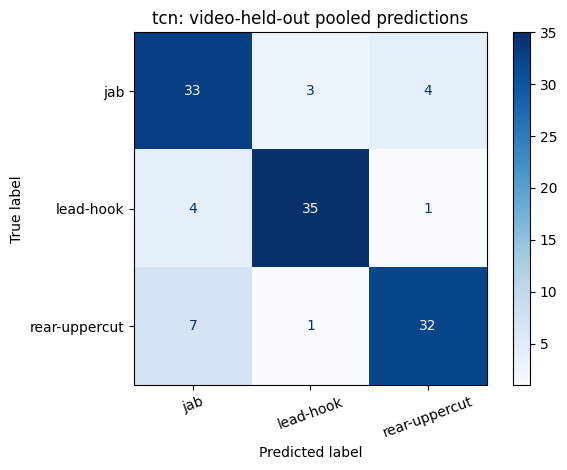


 stgcn 
 model  tested_videos  folds  pooled_accuracy  pooled_macro_f1  mean_fold_accuracy  mean_fold_macro_f1
stgcn            120      5            0.875         0.876284               0.875            0.875293

Per-fold:
       accuracy  macro_f1  test_videos
fold                                 
0     0.875000  0.877288         24.0
1     0.916667  0.916667         24.0
2     0.833333  0.837037         24.0
3     0.958333  0.958170         24.0
4     0.791667  0.787302         24.0

Class breakdown:
                precision    recall  f1-score   support

          jab      0.771     0.925     0.841        40
    lead-hook      0.947     0.900     0.923        40
rear-uppercut      0.941     0.800     0.865        40

     accuracy                          0.875       120
    macro avg      0.886     0.875     0.876       120
 weighted avg      0.886     0.875     0.876       120



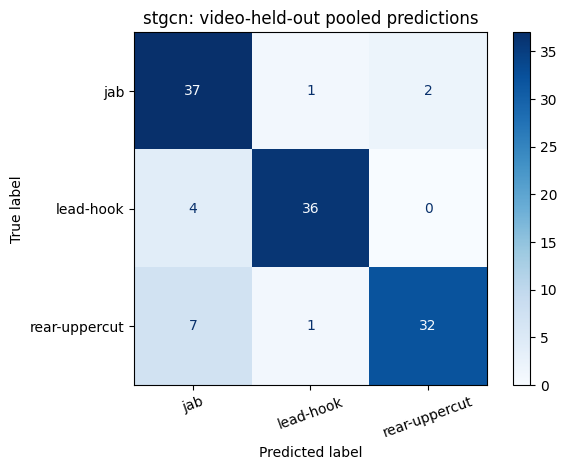


 tiny_dinat 
      model  tested_videos  folds  pooled_accuracy  pooled_macro_f1  mean_fold_accuracy  mean_fold_macro_f1
tiny_dinat            120      5         0.816667         0.816003            0.816667            0.815911

Per-fold:
       accuracy  macro_f1  test_videos
fold                                 
0     0.958333  0.958170         24.0
1     0.666667  0.660466         24.0
2     0.916667  0.916667         24.0
3     0.791667  0.787112         24.0
4     0.750000  0.757143         24.0

Class breakdown:
                precision    recall  f1-score   support

          jab      0.762     0.800     0.780        40
    lead-hook      0.857     0.900     0.878        40
rear-uppercut      0.833     0.750     0.789        40

     accuracy                          0.817       120
    macro avg      0.817     0.817     0.816       120
 weighted avg      0.817     0.817     0.816       120



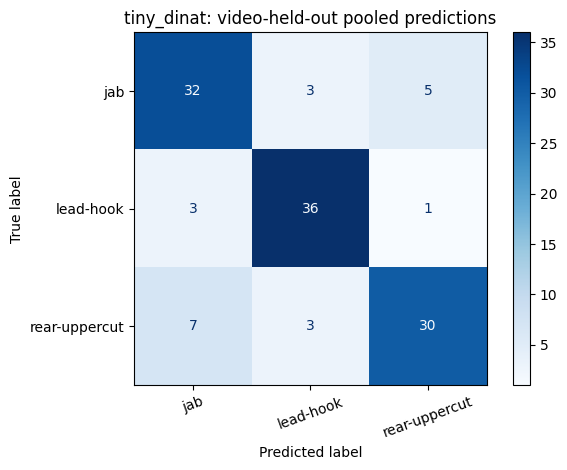

Results: /content/drive/MyDrive/newPerfectPunchData/stratified5_lite_v21


In [ ]:
if RUN_EXPERIMENTS:
    manifest = build_manifest()
    check_folds(manifest)
    audit_v12_data_files(manifest)
    predictions = evaluate_stratified5(manifest, MODELS_TO_RUN)
    summary = summarize_stratified5(predictions)
    print('Results:', RUN_DIR)
else:
    print('Training disabled. Set RUN_EXPERIMENTS=True in config and rerun this cell to start.')

## 12. Train a **separate final deployment model** on the full dataset

**Do not deploy a fold checkpoint as if it were trained on the full dataset.** After you select a model using CV, decide on the final epoch count from the CV best epochs (median is a starting point); refit on all labeled clips. This refit intentionally has **no test split** because the test results have already been used for model/epoch selection; for an independent production performance estimate, collect a new untouched video set. Training uses the exact original feature pipeline and training-only augmentation. You can export the final model to ONNX.

In [ ]:
def fit_final_model(manifest, model_name, epochs, filename=None):
    """Final refit on all available labeled videos after CV model selection."""
    if model_name not in MODEL_ZOO: raise ValueError(model_name)
    if int(epochs) < 1: raise ValueError('epochs must be positive')
    seed_everything(SEED + 50000)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = create_model(model_name).to(device)
    full_ds = BoxingDataset(manifest, augment=AUGMENT_TRAIN)
    labels = manifest.label.to_numpy(dtype=int)
    if SAMPLER_MODE == 'hook_x3':
        weights = np.where(labels==CLASS_NAMES.index('lead-hook'),3.,1.)
    elif SAMPLER_MODE == 'balanced':
        counts = np.bincount(labels,minlength=N_CLASSES)
        weights = 1. / np.maximum(counts[labels],1)
    elif SAMPLER_MODE == 'shuffle':
        weights = None
    else: raise ValueError(SAMPLER_MODE)
    sampler = WeightedRandomSampler(torch.as_tensor(weights,dtype=torch.double),
                                    num_samples=len(labels),replacement=True) if weights is not None else None
    loader = DataLoader(full_ds,batch_size=BATCH_SIZE,shuffle=sampler is None,
                        sampler=sampler,num_workers=NUM_WORKERS)
    optim = torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=EPOCHS)
    for epoch in range(1,int(epochs)+1):
        metrics = run_one_epoch(model,loader,device,optim)
        scheduler.step()
        if epoch == 1 or epoch % 10 == 0 or epoch == epochs:
            print(f'FINAL {model_name} ep={epoch}/{epochs}: acc={metrics["acc"]:.3f} loss={metrics["loss"]:.3f}')
    out = filename or os.path.join(RUN_DIR,f'FINAL_{model_name}.pt')
    torch.save({'state_dict':model.cpu().state_dict(),'model_name':model_name,
                'classes':CLASS_NAMES,'clip_frames':CLIP_FRAMES,'fps':TARGET_FPS,
                'n_channels':N_CHANNELS,'training_videos':len(manifest),'epochs':int(epochs),
                'augmentation_mode':AUGMENTATION_MODE, 'pose_variant': POSE_VARIANT,
                'role':'final_full_data_refit'},out)
    print('Final model saved to:',out)
    return out

# Example after FULL cross-validation:
# best_name = 'stgcn'   # use actual results
# cv = pd.read_csv(os.path.join(RUN_DIR,'stratified5_predictions.csv'))
# best_epochs = cv.loc[cv.model.eq(best_name),'best_epoch'].to_numpy()
# final_epochs = int(np.median(best_epochs))
# final_ckpt = fit_final_model(build_manifest(),best_name,final_epochs)

## 13. Real-video inference (exactly the training extraction and features) and ONNX export

`predict_video()` uses **the same 60-FPS MediaPipe skeleton resampling, reversal detection, first-frame padding, and `build_tensor()`** as training, with no augmentation. `export_onnx()` exports the trained model with the existing app-facing tensor contract: input `skeleton_volume` `(B,7,50,4,3)` and output `class_logits` `(B,3)`. The app's existing class label mapping can remain; verify that its ONNX provider/opset supports the chosen architecture before swapping in the new graph. A different model architecture cannot load old PyTorch `.pth` weights directly.

Note that ONNX exportability depends on your installed PyTorch/ONNX runtime; try exporting the selected final model on your actual Colab environment.

In [ ]:
def load_checkpoint(checkpoint, device=None):
    device = device or torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    meta = torch.load(checkpoint, map_location='cpu', weights_only=True)
    assert meta['clip_frames'] == CLIP_FRAMES and meta['classes'] == CLASS_NAMES
    assert meta.get('fps',TARGET_FPS) == TARGET_FPS and meta.get('n_channels',7) == N_CHANNELS
    if meta.get('pose_variant') is not None and meta['pose_variant'] != POSE_VARIANT:
        raise ValueError(f'Checkpoint trained using {meta["pose_variant"]} pose; active preprocessing is {POSE_VARIANT}')
    net = create_model(meta['model_name']).to(device)
    net.load_state_dict(meta['state_dict'])
    return net.eval(), meta, device

@torch.no_grad()
def predict_video(video_path, checkpoint):
    net, meta, device = load_checkpoint(checkpoint)
    clip = extract_best_clip(video_path)
    if clip is None: return None
    x = torch.from_numpy(build_tensor(prepare_raw_clip(clip))).unsqueeze(0).to(device)
    logits = net(x)
    probs = logits.softmax(1)[0].cpu().numpy()
    return {'predicted_label':CLASS_NAMES[int(probs.argmax())],
            'confidence':float(probs.max()),
            'probabilities':{name:float(prob) for name,prob in zip(CLASS_NAMES,probs)},
            'model':meta['model_name']}

def export_onnx(checkpoint, filename=None, opset=17):
    net, meta, _ = load_checkpoint(checkpoint,torch.device('cpu'))
    out = filename or os.path.join(RUN_DIR,f"{meta['model_name']}_final.onnx")
    dummy = torch.randn(1,N_CHANNELS,CLIP_FRAMES,N_ARM_JOINTS,3)
    torch.onnx.export(net,dummy,out,opset_version=opset,do_constant_folding=True,
                      input_names=['skeleton_volume'],output_names=['class_logits'],
                      dynamic_axes={'skeleton_volume':{0:'batch'},'class_logits':{0:'batch'}})
    print('ONNX saved:',out)
    return out

# predict_video('/content/drive/MyDrive/.../jab/jab_0001.mp4', final_ckpt)
# export_onnx(final_ckpt)

## 14. Notes about evaluation and deployment

- Class folder/file format preserved: `jab/jab_0001.mp4`, `hook/hook_0001.mp4`, `uppercut/uppercut_0001.mp4` (aliases `lead-hook`, `rear-uppercut`). Output canonical folders are `jab`, `lead-hook`, `rear-uppercut`.
- Data augmentation is **training-only**, and the `v12` setting is the original augmentation function from the uploaded notebook. Switching to `improved` does not change deployment preprocessing, but does change learned weights.
- The upload's 60 FPS skeleton resampling and leading edge padding **are crucial** for matching the existing backend. Do not replace them with the earlier v14 native-FPS/zero-padding extractor.
- The five models are deliberately compact. The optional original larger CNN may be used for comparison but is not included in `MODELS_TO_RUN`.
- Stratified 5-fold cross-validation only tests **new video recordings**, not unseen boxers; near-duplicate recordings and background/camera patterns can inflate scores.
- The `stratified5_predictions.csv` file records every held-out video's prediction, model, fold and probabilities, enabling error analysis. Keep the 5 stratified folds fixed for fair model comparisons.
- CV test data have been consulted when selecting the winning architecture; a truly independent performance report requires a new untouched set of videos.
- Production integration requires verifying ONNX operators, frame processing and input/output names as well as accuracy; the exported model graph is different from the original CNN even though its features and labels have the same schema.

## 15. Final ST-GCN training on all Lite videos

This cell uses the median best epoch from *Lite* 5-fold CV results if available. Otherwise it trains 54 epochs as a heuristic. All 120 Lite-processed clips are used for training; any reported training accuracy is in-sample, not held-out accuracy. The final checkpoint is saved in `stratified5_lite_v21`.


In [ ]:
# SECTION 15 — final deployment refit; do NOT rerun 5-fold training
import os
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader

manifest = build_manifest()
assert len(manifest) == 120, f"Expected the same 120-video dataset; got {len(manifest)}"
cv_path = os.path.join(RUN_DIR, 'stratified5_predictions.csv')
if os.path.isfile(cv_path):
    cv = pd.read_csv(cv_path)
    stgcn_folds = (cv.loc[cv['model'] == 'stgcn', ['fold', 'best_epoch']]
                     .drop_duplicates(subset=['fold']).sort_values('fold'))
    assert stgcn_folds['fold'].nunique() == N_SPLITS, (
        f"Expected {N_SPLITS} completed Lite ST-GCN folds, got {len(stgcn_folds)}"
    )
    FINAL_EPOCHS = max(1, int(round(stgcn_folds['best_epoch'].median())))
    print('Lite ST-GCN CV best epochs:', stgcn_folds['best_epoch'].tolist())
    print('Lite ST-GCN CV pooled held-out accuracy:',
          f"{(cv.loc[cv.model == 'stgcn', 'true'] == cv.loc[cv.model == 'stgcn', 'pred']).mean():.2%}")
else:
    FINAL_EPOCHS = 54  # only a starting heuristic from previous Heavy 5-fold, NOT a Lite result
    print('No Lite 5-fold predictions found. Using 54 epochs as a training heuristic.')
    print('This final refit has NO independent Lite held-out test accuracy.')
print('Full-data training epochs:', FINAL_EPOCHS)
print('Training config:', 'augmentation=', AUGMENTATION_MODE, 'sampler=', SAMPLER_MODE)

final_ckpt = fit_final_model(
    manifest,
    model_name='stgcn',
    epochs=FINAL_EPOCHS,
    filename=os.path.join(RUN_DIR, 'FINAL_stgcn_full120.pt'),
)

# Only an IN-SAMPLE sanity check; this is NOT held-out generalization accuracy.
net, meta, device = load_checkpoint(final_ckpt)
training_loader = DataLoader(
    BoxingDataset(manifest, augment=False),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)
training_metrics = run_one_epoch(net, training_loader, device)
print(f"IN-SAMPLE final training accuracy: {training_metrics['acc']:.2%}")
print(f"IN-SAMPLE final training macro-F1: {training_metrics['macro_f1']:.4f}")
print('NOTE: In-sample final training scores are NOT generalization accuracy.')
print('Final checkpoint:', final_ckpt)


Video counts: {'jab': 40, 'lead-hook': 40, 'rear-uppercut': 40} | Total: 120
Lite ST-GCN CV best epochs: [13, 38, 32, 74, 49]
Lite ST-GCN CV pooled held-out accuracy: 87.50%
Full-data training epochs: 38
Training config: augmentation= v12 sampler= hook_x3
FINAL stgcn ep=1/38: acc=0.550 loss=0.963
FINAL stgcn ep=10/38: acc=0.875 loss=0.506
FINAL stgcn ep=20/38: acc=0.892 loss=0.427
FINAL stgcn ep=30/38: acc=0.942 loss=0.353
FINAL stgcn ep=38/38: acc=0.942 loss=0.336
Final model saved to: /content/drive/MyDrive/newPerfectPunchData/stratified5_lite_v21/FINAL_stgcn_full120.pt
IN-SAMPLE final training accuracy: 93.33%
IN-SAMPLE final training macro-F1: 0.9342
NOTE: In-sample final training scores are NOT generalization accuracy.
Final checkpoint: /content/drive/MyDrive/newPerfectPunchData/stratified5_lite_v21/FINAL_stgcn_full120.pt


## 16. Optional legacy Gradio webcam (disabled by default)

**Use Section 17** for the guided countdown → single punch → automatic classification workflow.

This legacy webcam section is disabled by default to avoid accidentally starting a second webcam server. Previous versions used `gr.Video(format='mp4')`, which caused Gradio's preprocessing to invoke FFmpeg on browser-recorded WebM files. If that conversion fails, the inference function is never called.

If you specifically want the older Gradio input, change `ENABLE_LEGACY_GRADIO = True` in the code cell below. That version preserves the recorded video format and explicitly transcodes only when needed.


In [ ]:
# SECTION 16 — optional *legacy* Gradio webcam.
# This cell is safe to run before Section 17; it DOES NOT launch a second server.
ENABLE_LEGACY_GRADIO = False  # change only if you want the old Gradio recording UI

# Close a previously launched Section 16 server from this notebook session.
if 'recorded_demo' in globals() and recorded_demo is not None:
    try:
        recorded_demo.close()
        print('Previous Gradio webcam interface closed.')
    except Exception as exc:
        print('Could not close previous Gradio instance:', exc)
    recorded_demo = None

if ENABLE_LEGACY_GRADIO:
    import gradio as gr
    import os, tempfile, subprocess, shutil

    final_ckpt = os.path.join(RUN_DIR, 'FINAL_stgcn_full120.pt')
    assert os.path.isfile(final_ckpt), f'First run Section 15: {final_ckpt}'

    def classify_recorded_punch(video_path):
        if not video_path:
            return None, 'Record a short webcam video first.'
        # format=None below prevents Gradio from attempting a forced WebM→MP4 conversion.
        # Normalize at this point under our own control for consistent OpenCV decoding.
        with tempfile.TemporaryDirectory(prefix='perfectpunch_gradio_') as tmp:
            normalized = os.path.join(tmp, 'normalized.mp4')
            try:
                completed = subprocess.run([
                    'ffmpeg', '-hide_banner', '-loglevel', 'error', '-y',
                    '-i', os.fspath(video_path), '-an', '-c:v', 'libx264',
                    '-preset', 'veryfast', '-pix_fmt', 'yuv420p', normalized,
                ], capture_output=True, text=True, timeout=120)
            except Exception as exc:
                return None, f'Could not normalize camera video: {exc}'
            if completed.returncode != 0 or not os.path.isfile(normalized):
                return None, f'Video conversion failed: {completed.stderr[-600:]}'
            try:
                result = predict_video(normalized, final_ckpt)
            except Exception as exc:
                return None, f'Inference failed: {type(exc).__name__}: {exc}'
        if result is None:
            return None, 'No pose detected; keep upper body and arms visible.'
        return result['probabilities'], (
            f"Predicted: {result['predicted_label']} | "
            f"model confidence: {result['confidence']:.1%}"
        )

    with gr.Blocks(title='PerfectPunch — Legacy Gradio webcam') as recorded_demo:
        gr.Markdown('# PerfectPunch — legacy webcam test')
        gr.Markdown('Record a punch → stop recording → classify. Section 17 is recommended instead.')
        recorded_video = gr.Video(
            sources=['webcam', 'upload'], format=None,
            label='Record a short punch clip'
        )
        classify_btn = gr.Button('Classify this punch', variant='primary')
        label_out = gr.Label(num_top_classes=3, label='Prediction')
        status_out = gr.Textbox(label='Status')
        classify_btn.click(classify_recorded_punch, inputs=[recorded_video], outputs=[label_out, status_out])
    recorded_demo.launch(share=True, debug=False)
else:
    print('Legacy Gradio disabled. Run Section 17 for guided countdown and automatic classification.')


Legacy Gradio disabled. Run Section 17 for guided countdown and automatic classification.


## 17. Continuous Live Preview (MediaPipe **Lite**, consistent extractor variant)

Live webcam uses `LIVE_POSE_VARIANT=POSE_VARIANT`. Note that live pose detection uses `RunningMode.IMAGE` and irregular browser capture timestamps, whereas offline clips were extracted in `RunningMode.VIDEO` from source videos; the variant is matched, but temporal pre-processing is still not identical.


In [ ]:
# PerfectPunch — CONTINUOUS LIVE ST-GCN
# Replace your v19 Section 17 with this cell.  Run setup + model/feature
# definitions (Sections 0-13) first, and ensure Section 15 final checkpoint exists.
# In Colab first install Gradio once: %pip -q install 'gradio>=5,<7'

import os
import time
import urllib.request
import numpy as np
import torch
import mediapipe as mp
import gradio as gr
from mediapipe.tasks.python import BaseOptions, vision

# Use the SAME Pose variant as the training preprocessing.
LIVE_POSE_VARIANT = POSE_VARIANT
LIVE_WINDOW_SECONDS = 2.5   # rolling history used to locate reversal
LIVE_STREAM_EVERY = 0.25    # target callback interval, not actual camera fps
LIVE_MOTION_THRESHOLD = 0.20   # uncalibrated heuristic; no idle class exists
LIVE_MAX_IMAGE_WIDTH = 640

assert LIVE_POSE_VARIANT in ('lite', 'full', 'heavy')
LIVE_POSE_TASK = f'/content/pose_landmarker_{LIVE_POSE_VARIANT}.task'
if not os.path.isfile(LIVE_POSE_TASK):
    url = ('https://storage.googleapis.com/mediapipe-models/pose_landmarker/'
           f'pose_landmarker_{LIVE_POSE_VARIANT}/float16/latest/'
           f'pose_landmarker_{LIVE_POSE_VARIANT}.task')
    urllib.request.urlretrieve(url, LIVE_POSE_TASK)

LIVE_CKPT = os.path.join(RUN_DIR, 'FINAL_stgcn_full120.pt')
if not os.path.isfile(LIVE_CKPT):
    raise FileNotFoundError(f'Final ST-GCN checkpoint missing: {LIVE_CKPT}')

# Reuse the exact feature code and model definition from the notebook.
# NOTE: This runs in MediaPipe IMAGE mode, unlike the offline VIDEO mode.
live_net, live_meta, live_device = load_checkpoint(LIVE_CKPT)
live_landmarker = vision.PoseLandmarker.create_from_options(
    vision.PoseLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=LIVE_POSE_TASK),
        running_mode=vision.RunningMode.IMAGE,
        num_poses=1,
        min_pose_detection_confidence=0.5,
    )
)
print(f'Live pose: {LIVE_POSE_VARIANT} | model: {live_meta["model_name"]} | checkpoint pose: {live_meta.get("pose_variant", "unspecified")}')


def live_predict(frame, history):
    # Gradio State is isolated per browser session, unlike global deques.
    history = list(history or [])
    if frame is None:
        return None, 'Webcam not started.', history

    img = np.asarray(frame)
    if img.ndim != 3 or img.shape[2] < 3:
        return None, 'Invalid camera frame.', history
    rgb = np.ascontiguousarray(img[:, :, :3], dtype=np.uint8)

    if LIVE_MAX_IMAGE_WIDTH and rgb.shape[1] > LIVE_MAX_IMAGE_WIDTH:
        import cv2
        width = LIVE_MAX_IMAGE_WIDTH
        height = max(1, int(round(rgb.shape[0] * width / rgb.shape[1])))
        rgb = cv2.resize(rgb, (width, height), interpolation=cv2.INTER_AREA)
        rgb = np.ascontiguousarray(rgb)

    result = live_landmarker.detect(
        mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
    )
    if not result.pose_world_landmarks:
        # Prune old samples; no fake skeleton inserted on failed detection.
        now = time.monotonic()
        history = [(t, s) for t, s in history if now - t <= LIVE_WINDOW_SECONDS + 0.5]
        return None, 'No pose detected. Keep upper body visible.', history

    now = time.monotonic()
    skeleton = normalize_skeleton(result.pose_world_landmarks[0])  # (33,4)
    history.append((now, skeleton))
    history = [(t, s) for t, s in history if now - t <= LIVE_WINDOW_SECONDS + 0.5][-160:]
    if len(history) < 5 or history[-1][0] - history[0][0] < 1.2:
        return None, f'Collecting pose frames: {len(history)}', history

    # Server callback timestamps are a rough proxy for capture times.
    ts = np.asarray([t for t, _ in history], dtype=np.float64)
    skels = np.stack([s for _, s in history]).astype(np.float32)
    t0 = max(ts[0], ts[-1] - LIVE_WINDOW_SECONDS)
    target_ts = np.arange(t0, ts[-1] + 1e-8, 1.0 / TARGET_FPS)
    if len(target_ts) < CLIP_FRAMES:
        return None, 'Waiting for at least 50 interpolated frames.', history

    lo = np.clip(np.searchsorted(ts, target_ts, side='right') - 1, 0, len(ts)-1)
    hi = np.clip(lo + 1, 0, len(ts)-1)
    dt = ts[hi] - ts[lo]
    alpha = np.divide(target_ts - ts[lo], dt,
                      out=np.zeros(len(target_ts), dtype=np.float64), where=dt > 1e-8)
    sequence = (skels[lo] * (1.0-alpha[:, None, None]) +
                skels[hi] * alpha[:, None, None]).astype(np.float32)

    # No idle class was trained; suppress low-motion intervals heuristically.
    wrist_motion = float(np.max(np.ptp(sequence[:, [15,16], :3], axis=0)))
    if wrist_motion < LIVE_MOTION_THRESHOLD:
        return None, f'Waiting for a punch (motion={wrist_motion:.2f}).', history

    clip_end, peak, axis, reversal_found = find_reversal_frame(sequence, TARGET_FPS)
    clip = prepare_raw_clip(sequence[max(0, clip_end + 1 - CLIP_FRAMES):clip_end + 1])
    x = torch.from_numpy(build_tensor(clip)).unsqueeze(0).to(live_device)
    with torch.inference_mode():
        prob = live_net(x).softmax(dim=1)[0].cpu().numpy()
    k = int(prob.argmax())
    scores = {name: float(p) for name, p in zip(CLASS_NAMES, prob)}
    status = (f'{CLASS_NAMES[k]} ({prob[k]:.1%} model confidence) | '
              f'axis={axis}, reversal={reversal_found}, '
              f'received frames={len(history)}. Not calibrated.')
    return scores, status, history


def reset_live_buffer():
    return None, 'Buffer reset. Perform a punch to begin.', []


# Avoid launching the old Gradio Video interface in Section 16.
try:
    if 'live_demo' in globals():
        live_demo.close()
except Exception:
    pass

with gr.Blocks(title='PerfectPunch — Live ST-GCN') as live_demo:
    gr.Markdown('# PerfectPunch — Live ST-GCN')
    gr.Markdown('Start the webcam. The prediction updates during the camera stream. '
                'Experimental: Colab can drop frames; no idle/no-punch class.')
    history_state = gr.State(value=[])
    camera = gr.Image(sources=['webcam'], type='numpy', streaming=True, label='Live camera')
    prediction = gr.Label(num_top_classes=3, label='Latest prediction')
    status = gr.Textbox(label='Status')
    camera.stream(live_predict, inputs=[camera, history_state],
                  outputs=[prediction, status, history_state],
                  stream_every=LIVE_STREAM_EVERY, time_limit=300,
                  concurrency_limit=1, show_progress='hidden')
    gr.Button('Reset motion buffer').click(reset_live_buffer,
                                           outputs=[prediction, status, history_state])

live_demo.launch(share=True, debug=False)


Live pose: lite | model: stgcn | checkpoint pose: lite
Closing server running on port: 7860
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d9368d837a3284b1f4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
